Household Power Consumption — Time-Series Analysis
CMPE 255 — Part 1: Time-Series Dataset

This project analyzes household electricity consumption using exploratory data analysis, data cleaning, time-series visualizations, clustering, anomaly detection, and automated machine learning.

Dataset: Individual Household Electric Power Consumption

Objectives:
- Understand electricity consumption patterns over time.
- Identify missing values and unusual consumption behavior.
- Prepare time-series features for machine learning.
- Discover consumption patterns using clustering.
- Predict electricity consumption using AutoViML.

In [1]:
# Step 1: Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings("ignore")

# Visualization settings
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# Step 2: Upload the dataset
from google.colab import files

uploaded = files.upload()

print("Uploaded files:", list(uploaded.keys()))

Saving household_power_consumption.txt to household_power_consumption.txt
Uploaded files: ['household_power_consumption.txt']


In [3]:
# Step 3: Load household power consumption data
file_path = "household_power_consumption.txt"

df = pd.read_csv(
    file_path,
    sep=";",
    na_values=["?"],
    low_memory=False
)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (2075259, 9)


,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,16/12/2006,17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0
1,16/12/2006,17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0
2,16/12/2006,17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0
3,16/12/2006,17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0
4,16/12/2006,17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0


In [4]:
# Step 4: Examine dataset structure
print("Dataset information:")
df.info()

print("\nSummary statistics:")
display(df.describe(include="all"))

print("\nMissing values:")
display(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2075259 entries, 0 to 2075258
Data columns (total 9 columns):
 #   Column                 Dtype  
---  ------                 -----  
 0   Date                   object 
 1   Time                   object 
 2   Global_active_power    float64
 3   Global_reactive_power  float64
 4   Voltage                float64
 5   Global_intensity       float64
 6   Sub_metering_1         float64
 7   Sub_metering_2         float64
 8   Sub_metering_3         float64
dtypes: float64(7), object(2)
memory usage: 142.5+ MB

Summary statistics:


,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
count,2075259,2075259,2.049280e+06,2.049280e+06,2.049280e+06,2.049280e+06,2.049280e+06,2.049280e+06,2.049280e+06
unique,1442,1440,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,25/11/2010,17:24:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,1440,1442,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,NaN,1.091615e+00,1.237145e-01,2.408399e+02,4.627759e+00,1.121923e+00,1.298520e+00,6.458447e+00
std,NaN,NaN,1.057294e+00,1.127220e-01,3.239987e+00,4.444396e+00,6.153031e+00,5.822026e+00,8.437154e+00
min,NaN,NaN,7.600000e-02,0.000000e+00,2.232000e+02,2.000000e-01,0.000000e+00,0.000000e+00,0.000000e+00
25%,NaN,NaN,3.080000e-01,4.800000e-02,2.389900e+02,1.400000e+00,0.000000e+00,0.000000e+00,0.000000e+00
50%,NaN,NaN,6.020000e-01,1.000000e-01,2.410100e+02,2.600000e+00,0.000000e+00,0.000000e+00,1.000000e+00
75%,NaN,NaN,1.528000e+00,1.940000e-01,2.428900e+02,6.400000e+00,0.000000e+00,1.000000e+00,1.700000e+01



Missing values:


,0
Date,0
Time,0
Global_active_power,25979
Global_reactive_power,25979
Voltage,25979
Global_intensity,25979
Sub_metering_1,25979
Sub_metering_2,25979
Sub_metering_3,25979



Duplicate rows: 0


In [5]:
# Step 5: Convert date and time into datetime
df["datetime"] = pd.to_datetime(
    df["Date"] + " " + df["Time"],
    format="%d/%m/%Y %H:%M:%S",
    errors="coerce"
)

# Sort chronologically
df = df.sort_values("datetime")

# Set datetime as index
df = df.set_index("datetime")

# Remove original date and time columns
df = df.drop(columns=["Date", "Time"])

print("Time-series dataset shape:", df.shape)
display(df.head())

Time-series dataset shape: (2075259, 7)


,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
datetime,,,,,,,
2006-12-16 17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0
2006-12-16 17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0
2006-12-16 17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0
2006-12-16 17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0
2006-12-16 17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0


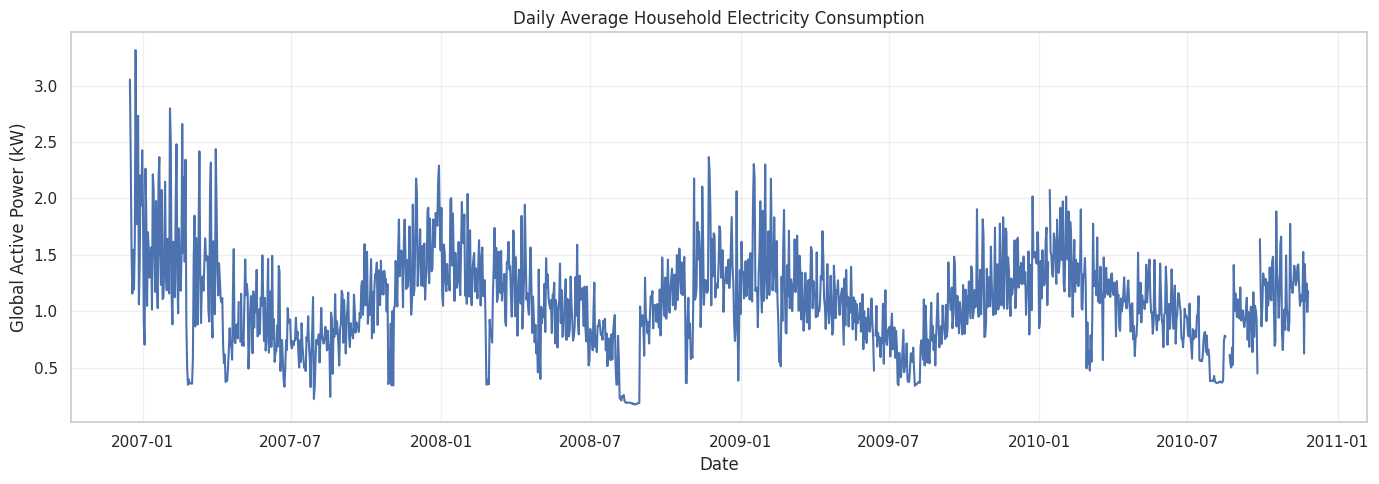

In [6]:
# Step 6: Daily electricity consumption trends
daily_power = df["Global_active_power"].resample("D").mean()

plt.figure(figsize=(14, 5))
plt.plot(daily_power.index, daily_power.values)

plt.title("Daily Average Household Electricity Consumption")
plt.xlabel("Date")
plt.ylabel("Global Active Power (kW)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Missing Value Summary:


,Missing Values,Missing Percentage
Global_active_power,25979,1.25
Global_reactive_power,25979,1.25
Voltage,25979,1.25
Global_intensity,25979,1.25
Sub_metering_1,25979,1.25
Sub_metering_2,25979,1.25
Sub_metering_3,25979,1.25


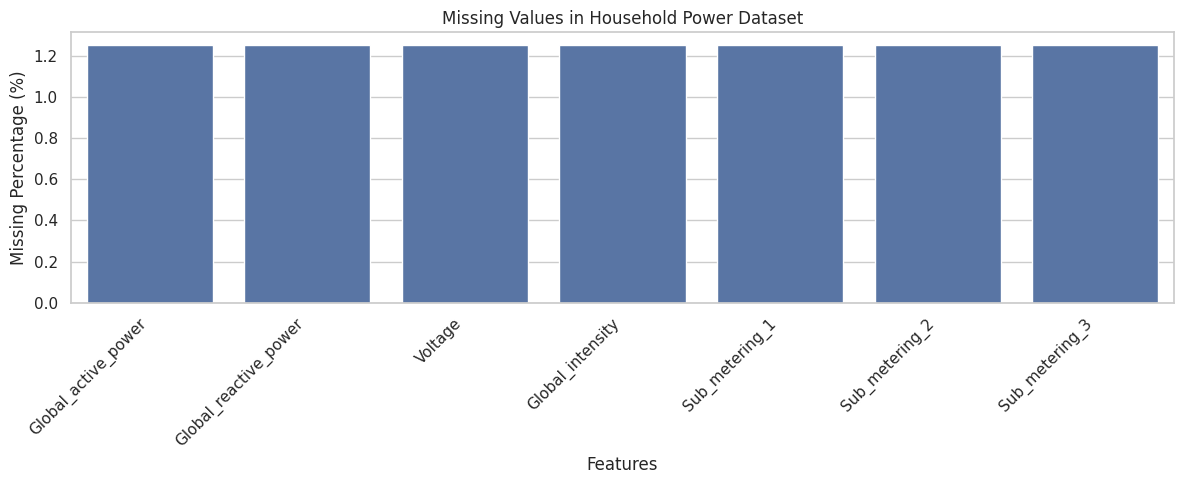

In [7]:
# Step 7: Analyze missing values

# Count missing values for each column
missing_values = df.isnull().sum()

# Calculate missing percentages
missing_percent = (missing_values / len(df)) * 100

# Create missing value summary
missing_summary = pd.DataFrame({
    "Missing Values": missing_values,
    "Missing Percentage": missing_percent.round(2)
})

print("Missing Value Summary:")
display(missing_summary)

# Visualize missing values
plt.figure(figsize=(12, 5))

sns.barplot(
    x=missing_summary.index,
    y=missing_summary["Missing Percentage"]
)

plt.title("Missing Values in Household Power Dataset")
plt.xlabel("Features")
plt.ylabel("Missing Percentage (%)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [8]:
# Step 8: Clean the dataset

# Preserve original dataset
df_clean = df.copy()

# Ensure measurements are numeric
for col in df_clean.columns:
    df_clean[col] = pd.to_numeric(
        df_clean[col],
        errors="coerce"
    )

print("Missing values before cleaning:")
display(df_clean.isnull().sum())

# Fill missing values using time interpolation
df_clean = df_clean.interpolate(
    method="time",
    limit_direction="both"
)

print("\nMissing values after cleaning:")
display(df_clean.isnull().sum())

print("\nCleaned dataset shape:", df_clean.shape)

Missing values before cleaning:


,0
Global_active_power,25979
Global_reactive_power,25979
Voltage,25979
Global_intensity,25979
Sub_metering_1,25979
Sub_metering_2,25979
Sub_metering_3,25979



Missing values after cleaning:


,0
Global_active_power,0
Global_reactive_power,0
Voltage,0
Global_intensity,0
Sub_metering_1,0
Sub_metering_2,0
Sub_metering_3,0



Cleaned dataset shape: (2075259, 7)


In [9]:
# Step 9: Validate cleaned data

print("Duplicate timestamps:",
      df_clean.index.duplicated().sum())

print("\nNegative measurement values:")
numeric_columns = df_clean.select_dtypes(
    include=[np.number]
).columns

negative_counts = (df_clean[numeric_columns] < 0).sum()
display(negative_counts)

print("\nDataset information:")
df_clean.info()

print("\nSummary statistics:")
display(df_clean.describe())

Duplicate timestamps: 0

Negative measurement values:


,0
Global_active_power,0
Global_reactive_power,0
Voltage,0
Global_intensity,0
Sub_metering_1,0
Sub_metering_2,0
Sub_metering_3,0



Dataset information:
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 2075259 entries, 2006-12-16 17:24:00 to 2010-11-26 21:02:00
Data columns (total 7 columns):
 #   Column                 Dtype  
---  ------                 -----  
 0   Global_active_power    float64
 1   Global_reactive_power  float64
 2   Voltage                float64
 3   Global_intensity       float64
 4   Sub_metering_1         float64
 5   Sub_metering_2         float64
 6   Sub_metering_3         float64
dtypes: float64(7)
memory usage: 126.7 MB

Summary statistics:


,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
count,2.075259e+06,2.075259e+06,2.075259e+06,2.075259e+06,2.075259e+06,2.075259e+06,2.075259e+06
mean,1.090280e+00,1.236492e-01,2.408328e+02,4.621481e+00,1.109485e+00,1.289229e+00,6.442386e+00
std,1.052628e+00,1.124194e-01,3.237763e+00,4.424361e+00,6.115843e+00,5.786613e+00,8.415860e+00
min,7.600000e-02,0.000000e+00,2.232000e+02,2.000000e-01,0.000000e+00,0.000000e+00,0.000000e+00
25%,3.100000e-01,4.800000e-02,2.389900e+02,1.400000e+00,0.000000e+00,0.000000e+00,0.000000e+00
50%,6.140000e-01,1.000000e-01,2.410000e+02,2.751585e+00,0.000000e+00,0.000000e+00,1.000000e+00
75%,1.528000e+00,1.940000e-01,2.428700e+02,6.400000e+00,0.000000e+00,1.000000e+00,1.700000e+01
max,1.112200e+01,1.390000e+00,2.541500e+02,4.840000e+01,8.800000e+01,8.000000e+01,3.100000e+01


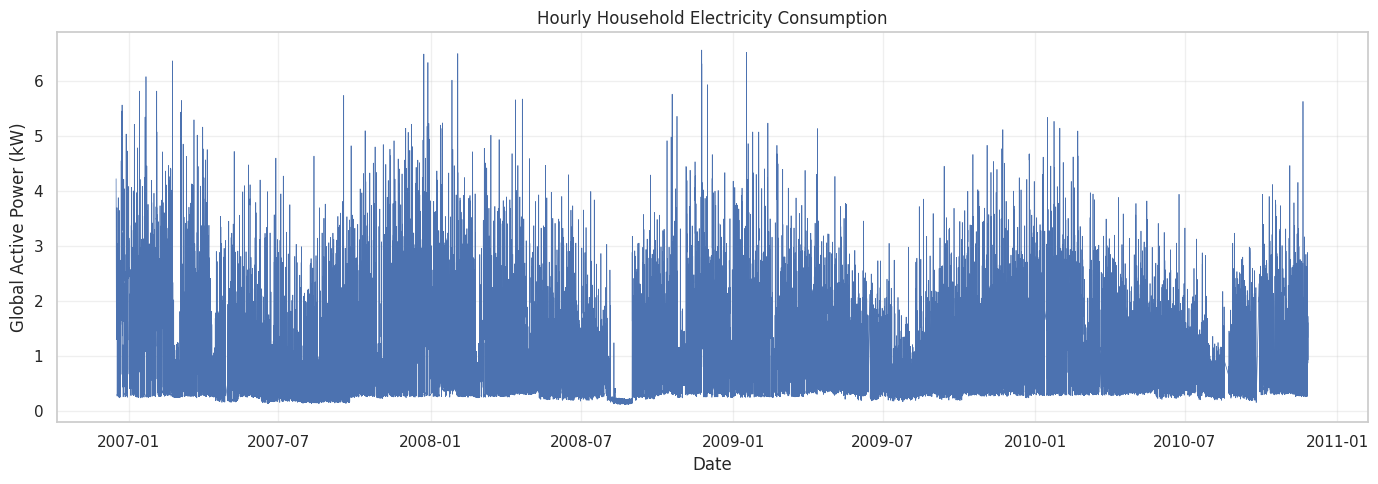

In [10]:
# Step 10: Analyze hourly electricity consumption

hourly_power = df_clean[
    "Global_active_power"
].resample("h").mean()

plt.figure(figsize=(14, 5))
plt.plot(
    hourly_power.index,
    hourly_power.values,
    linewidth=0.5
)

plt.title("Hourly Household Electricity Consumption")
plt.xlabel("Date")
plt.ylabel("Global Active Power (kW)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

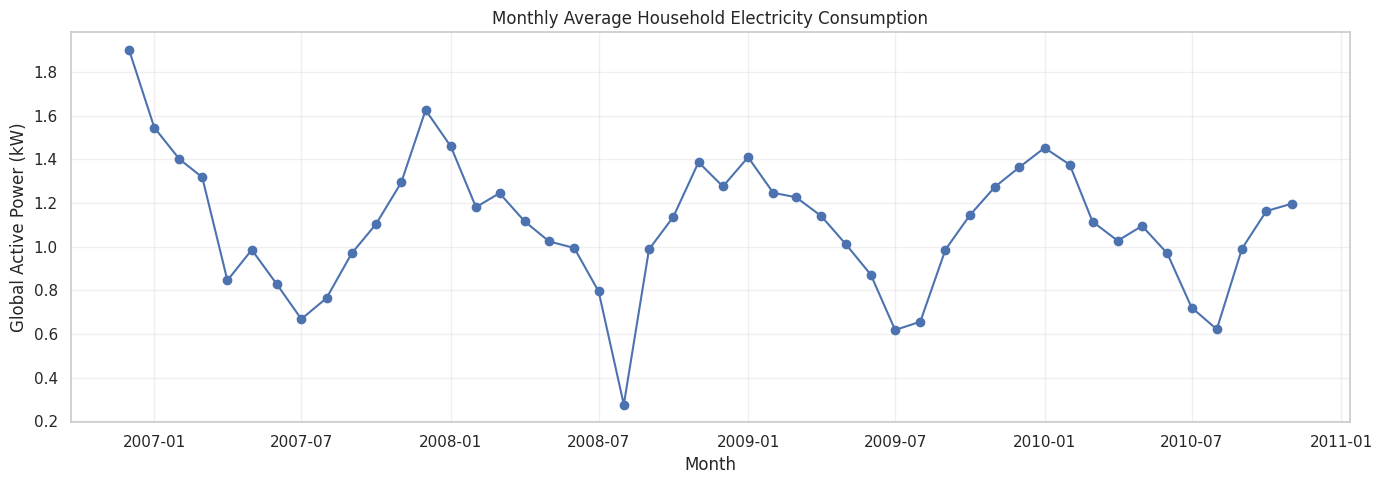

In [11]:
# Step 11: Analyze monthly electricity consumption

monthly_power = df_clean[
    "Global_active_power"
].resample("MS").mean()

plt.figure(figsize=(14, 5))

plt.plot(
    monthly_power.index,
    monthly_power.values,
    marker="o"
)

plt.title("Monthly Average Household Electricity Consumption")
plt.xlabel("Month")
plt.ylabel("Global Active Power (kW)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

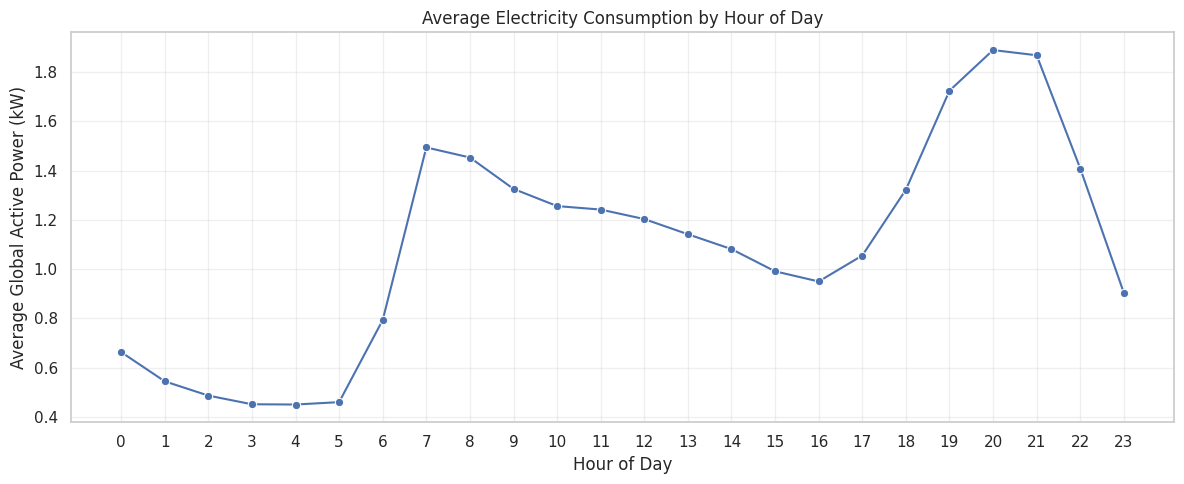

In [12]:
# Step 12: Average electricity usage by hour

df_clean["hour"] = df_clean.index.hour

hourly_average = df_clean.groupby("hour")[
    "Global_active_power"
].mean()

plt.figure(figsize=(12, 5))

sns.lineplot(
    x=hourly_average.index,
    y=hourly_average.values,
    marker="o"
)

plt.title("Average Electricity Consumption by Hour of Day")
plt.xlabel("Hour of Day")
plt.ylabel("Average Global Active Power (kW)")
plt.xticks(range(0, 24))
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

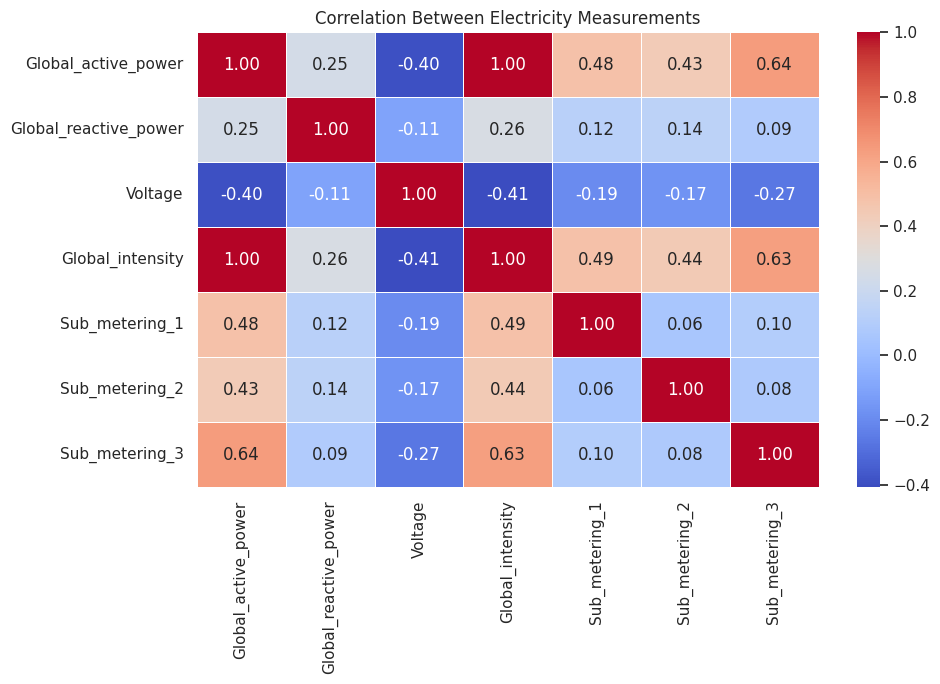

In [13]:
# Step 13: Analyze correlations between measurements

# Select original electricity measurements
power_features = [
    "Global_active_power",
    "Global_reactive_power",
    "Voltage",
    "Global_intensity",
    "Sub_metering_1",
    "Sub_metering_2",
    "Sub_metering_3"
]

correlation_matrix = df_clean[
    power_features
].corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Between Electricity Measurements")
plt.tight_layout()
plt.show()

In [14]:
# Step 14: Create time-based features

# Preserve the cleaned dataset
df_features = df_clean.copy()

# Extract time information
df_features["hour"] = df_features.index.hour
df_features["day_of_week"] = df_features.index.dayofweek
df_features["day"] = df_features.index.day
df_features["month"] = df_features.index.month
df_features["year"] = df_features.index.year

# Identify weekends
df_features["is_weekend"] = (
    df_features["day_of_week"] >= 5
).astype(int)

# Identify seasons
def get_season(month):
    if month in [12, 1, 2]:
        return "Winter"
    elif month in [3, 4, 5]:
        return "Spring"
    elif month in [6, 7, 8]:
        return "Summer"
    else:
        return "Fall"

df_features["season"] = df_features["month"].apply(
    get_season
)

print("Dataset shape after feature engineering:",
      df_features.shape)

display(df_features.head())

Dataset shape after feature engineering: (2075259, 14)


,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3,hour,day_of_week,day,month,year,is_weekend,season
datetime,,,,,,,,,,,,,,
2006-12-16 17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0,17,5,16,12,2006,1,Winter
2006-12-16 17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0,17,5,16,12,2006,1,Winter
2006-12-16 17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0,17,5,16,12,2006,1,Winter
2006-12-16 17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0,17,5,16,12,2006,1,Winter
2006-12-16 17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0,17,5,16,12,2006,1,Winter


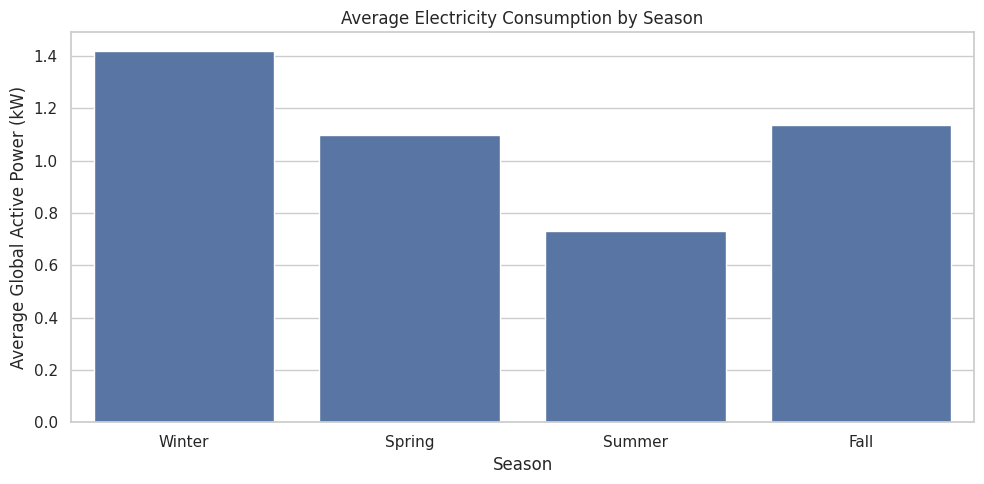

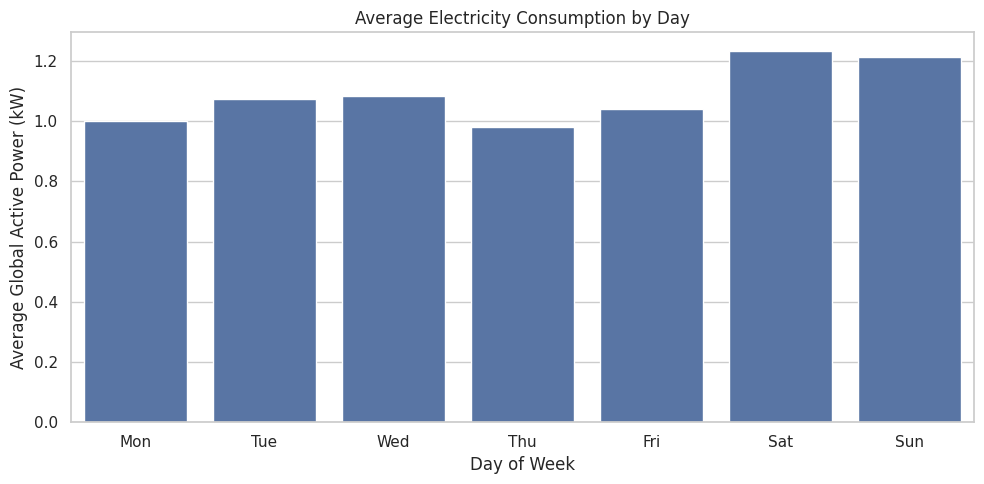

In [15]:
# Step 15: Compare electricity consumption patterns

season_order = [
    "Winter", "Spring", "Summer", "Fall"
]

seasonal_average = (
    df_features.groupby("season")[
        "Global_active_power"
    ].mean().reindex(season_order)
)

plt.figure(figsize=(10, 5))
sns.barplot(
    x=seasonal_average.index,
    y=seasonal_average.values
)

plt.title("Average Electricity Consumption by Season")
plt.xlabel("Season")
plt.ylabel("Average Global Active Power (kW)")
plt.tight_layout()
plt.show()

# Average consumption by day of week
weekly_average = df_features.groupby(
    "day_of_week"
)["Global_active_power"].mean()

day_names = [
    "Mon", "Tue", "Wed", "Thu",
    "Fri", "Sat", "Sun"
]

plt.figure(figsize=(10, 5))
sns.barplot(
    x=day_names,
    y=weekly_average.reindex(range(7)).values
)

plt.title("Average Electricity Consumption by Day")
plt.xlabel("Day of Week")
plt.ylabel("Average Global Active Power (kW)")
plt.tight_layout()
plt.show()

Original dataset shape: (2075259, 7)
Cleaned dataset shape: (2075259, 8)
Feature dataset shape: (2075259, 14)

Missing values:


,0
Global_active_power,0
Global_reactive_power,0
Voltage,0
Global_intensity,0
Sub_metering_1,0
Sub_metering_2,0
Sub_metering_3,0
hour,0
day_of_week,0
day,0



Duplicate timestamps: 0

Electricity consumption statistics:


,Global_active_power
count,2.075259e+06
mean,1.090280e+00
std,1.052628e+00
min,7.600000e-02
25%,3.100000e-01
50%,6.140000e-01
75%,1.528000e+00
max,1.112200e+01


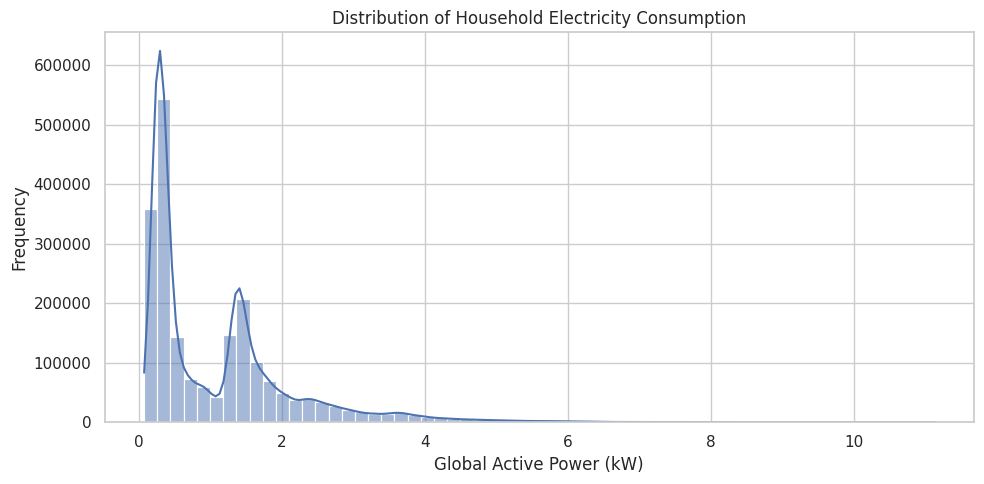

In [16]:
# Step 16: Final EDA checks

print("Original dataset shape:", df.shape)
print("Cleaned dataset shape:", df_clean.shape)
print("Feature dataset shape:", df_features.shape)

print("\nMissing values:")
display(df_features.isnull().sum())

print("\nDuplicate timestamps:",
      df_features.index.duplicated().sum())

print("\nElectricity consumption statistics:")
display(
    df_features["Global_active_power"].describe()
)

# Visualize the distribution of electricity demand
plt.figure(figsize=(10, 5))

sns.histplot(
    df_features["Global_active_power"].dropna(),
    bins=60,
    kde=True
)

plt.title("Distribution of Household Electricity Consumption")
plt.xlabel("Global Active Power (kW)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

# Part 1b — Clustering & Anomaly Detection

Hourly aggregated measurements is used rather than millions of individual minute-level observations. This makes clustering more manageable and allows us to identify different hourly electricity consumption patterns.

In [17]:
# Step 17: Prepare hourly clustering data

power_columns = [
    "Global_active_power",
    "Global_reactive_power",
    "Voltage",
    "Global_intensity",
    "Sub_metering_1",
    "Sub_metering_2",
    "Sub_metering_3"
]

# Aggregate electricity measurements hourly
hourly_df = df_clean[power_columns].resample("h").mean()

# Record how many measurements were available per hour
hourly_df["observed_minutes"] = (
    df[power_columns[0]].resample("h").count()
)

# Remove hours with insufficient observed measurements
hourly_df = hourly_df[
    hourly_df["observed_minutes"] >= 30
].copy()

# Add temporal features
hourly_df["hour"] = hourly_df.index.hour
hourly_df["day_of_week"] = hourly_df.index.dayofweek
hourly_df["month"] = hourly_df.index.month
hourly_df["is_weekend"] = (
    hourly_df["day_of_week"] >= 5
).astype(int)

print("Hourly dataset shape:", hourly_df.shape)
display(hourly_df.head())

Hourly dataset shape: (34157, 12)


,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3,observed_minutes,hour,day_of_week,month,is_weekend
datetime,,,,,,,,,,,,
2006-12-16 17:00:00,4.222889,0.229000,234.643889,18.100000,0.0,0.527778,16.861111,36,17,5,12,1
2006-12-16 18:00:00,3.632200,0.080033,234.580167,15.600000,0.0,6.716667,16.866667,60,18,5,12,1
2006-12-16 19:00:00,3.400233,0.085233,233.232500,14.503333,0.0,1.433333,16.683333,60,19,5,12,1
2006-12-16 20:00:00,3.268567,0.075100,234.071500,13.916667,0.0,0.000000,16.783333,60,20,5,12,1
2006-12-16 21:00:00,3.056467,0.076667,237.158667,13.046667,0.0,0.416667,17.216667,60,21,5,12,1


In [18]:
# Step 18: Select and scale clustering features

from sklearn.preprocessing import StandardScaler

cluster_features = power_columns + [
    "hour",
    "day_of_week",
    "is_weekend"
]

X_cluster = hourly_df[cluster_features].copy()

# Verify missing and infinite values
X_cluster = X_cluster.replace(
    [np.inf, -np.inf], np.nan
)

X_cluster = X_cluster.dropna()

# Align hourly dataset
hourly_df = hourly_df.loc[X_cluster.index].copy()

# Standardize numerical features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_cluster)

print("Clustering matrix shape:", X_scaled.shape)
print("Features used:", cluster_features)

Clustering matrix shape: (34157, 10)
Features used: ['Global_active_power', 'Global_reactive_power', 'Voltage', 'Global_intensity', 'Sub_metering_1', 'Sub_metering_2', 'Sub_metering_3', 'hour', 'day_of_week', 'is_weekend']


,K,Inertia,Silhouette Score
0,2,39019.593580,0.269818
1,3,33353.564991,0.244001
2,4,28414.401028,0.257533
3,5,24958.155216,0.268303
4,6,22649.595050,0.231561
5,7,20621.782753,0.247497
6,8,19601.110096,0.249996


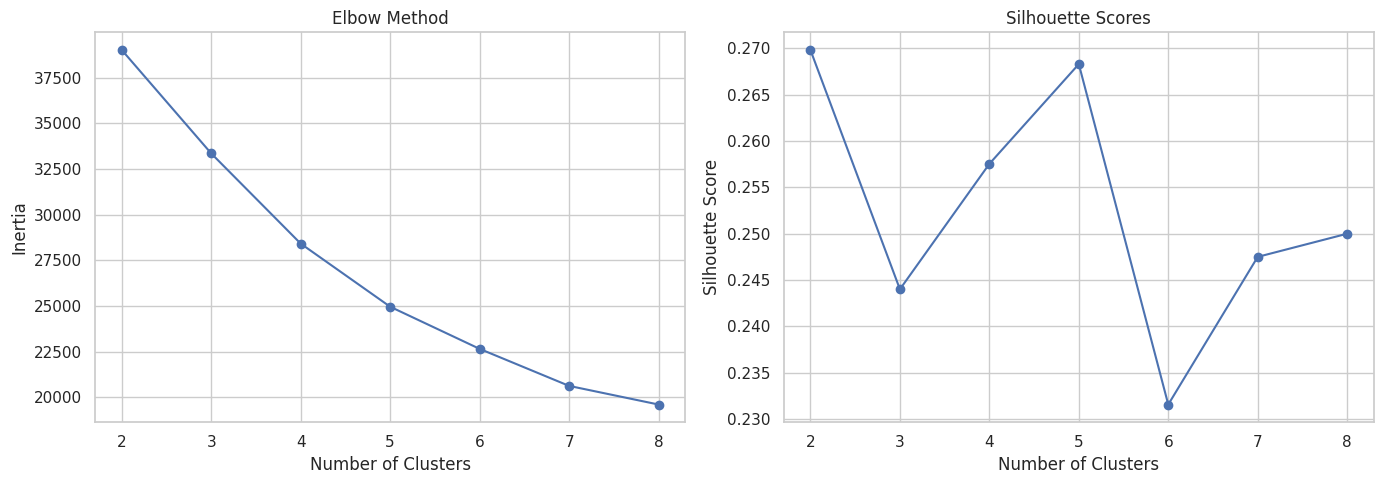

Best K based on silhouette score: 2


In [19]:
# Step 19: Evaluate different cluster counts

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Reproducible sample for evaluation
rng = np.random.default_rng(42)
sample_size = min(5000, len(X_scaled))

sample_idx = rng.choice(
    len(X_scaled),
    size=sample_size,
    replace=False
)

X_sample = X_scaled[sample_idx]

k_values = range(2, 9)
inertias = []
silhouette_scores = []

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_sample)

    inertias.append(kmeans.inertia_)

    score = silhouette_score(
        X_sample,
        labels,
        sample_size=min(2000, len(X_sample)),
        random_state=42
    )

    silhouette_scores.append(score)

evaluation = pd.DataFrame({
    "K": list(k_values),
    "Inertia": inertias,
    "Silhouette Score": silhouette_scores
})

display(evaluation)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(list(k_values), inertias, marker="o")
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Number of Clusters")
axes[0].set_ylabel("Inertia")

axes[1].plot(
    list(k_values),
    silhouette_scores,
    marker="o"
)
axes[1].set_title("Silhouette Scores")
axes[1].set_xlabel("Number of Clusters")
axes[1].set_ylabel("Silhouette Score")

plt.tight_layout()
plt.show()

best_k = int(
    evaluation.loc[
        evaluation["Silhouette Score"].idxmax(), "K"
    ]
)

print("Best K based on silhouette score:", best_k)

Number of hours per cluster:


,count
cluster,
0,12748
1,21409


,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
cluster,,,,,,,
0,2.033,0.144,239.342,8.547,2.711,2.745,14.040
1,0.531,0.112,241.731,2.294,0.176,0.437,1.944


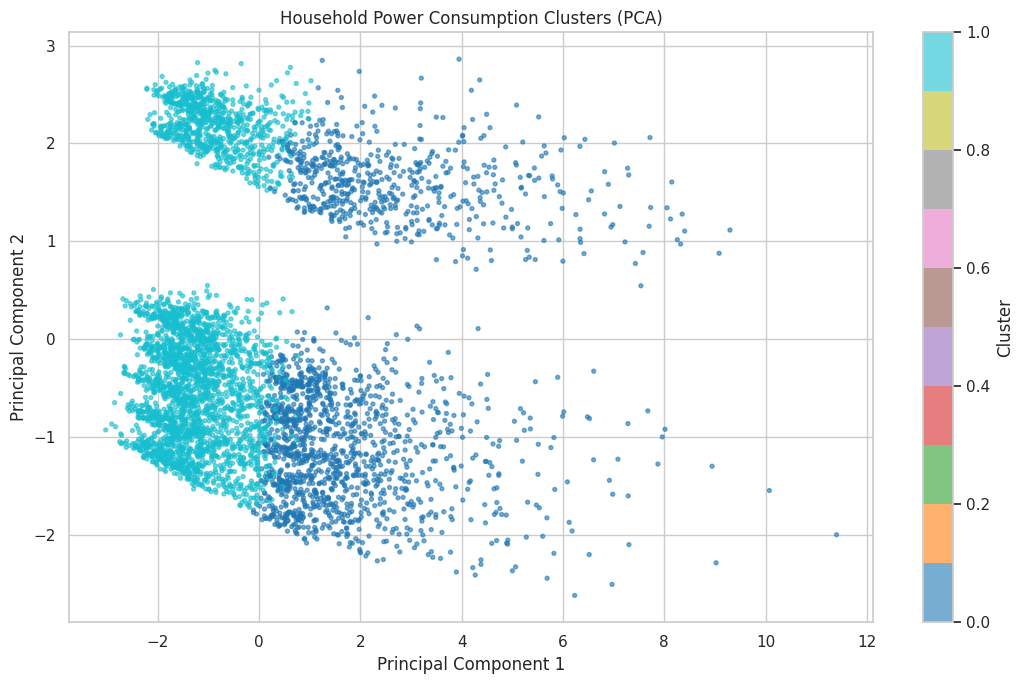

Variance explained by first two components: 53.63 %


In [20]:
# Step 20: Train final K-Means clustering model

from sklearn.decomposition import PCA

final_kmeans = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10
)

hourly_df["cluster"] = final_kmeans.fit_predict(
    X_scaled
)

print("Number of hours per cluster:")
display(
    hourly_df["cluster"].value_counts().sort_index()
)

# Summarize cluster characteristics
cluster_summary = hourly_df.groupby("cluster")[
    power_columns
].mean().round(3)

display(cluster_summary)

# PCA for two-dimensional visualization
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

# Plot a sample to avoid overcrowding
plot_idx = rng.choice(
    len(X_pca),
    size=min(5000, len(X_pca)),
    replace=False
)

plt.figure(figsize=(11, 7))

scatter = plt.scatter(
    X_pca[plot_idx, 0],
    X_pca[plot_idx, 1],
    c=hourly_df["cluster"].to_numpy()[plot_idx],
    cmap="tab10",
    s=8,
    alpha=0.6
)

plt.colorbar(scatter, label="Cluster")
plt.title("Household Power Consumption Clusters (PCA)")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.tight_layout()
plt.show()

print(
    "Variance explained by first two components:",
    round(pca.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

Anomaly detection results:


,count
anomaly_label,
1,32449
-1,1708


Potential anomalies: 1708
Anomaly percentage: 5.0 %


,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
is_anomaly,,,,,,,
0,0.977,0.118,240.995,4.141,0.691,0.736,6.157
1,3.262,0.237,237.883,13.881,9.303,11.985,12.173


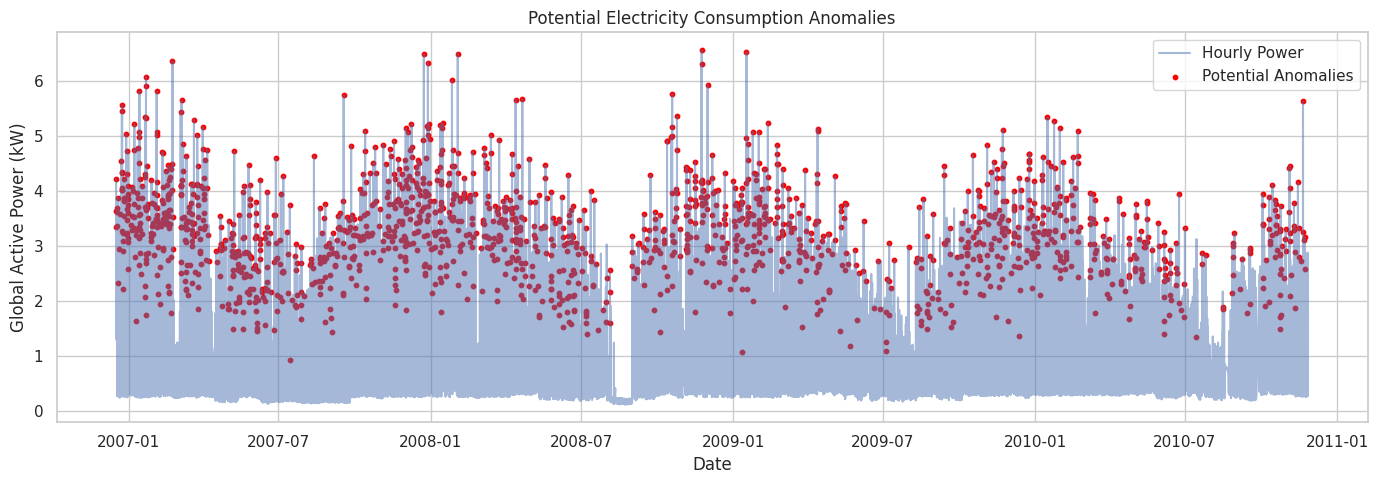

In [21]:
# Step 21: Detect unusual consumption patterns

from sklearn.ensemble import IsolationForest

isolation_model = IsolationForest(
    n_estimators=200,
    contamination=0.05,
    random_state=42,
    n_jobs=-1
)

hourly_df["anomaly_label"] = (
    isolation_model.fit_predict(X_scaled)
)

hourly_df["is_anomaly"] = (
    hourly_df["anomaly_label"] == -1
).astype(int)

print("Anomaly detection results:")
display(hourly_df["anomaly_label"].value_counts())

print(
    "Potential anomalies:",
    hourly_df["is_anomaly"].sum()
)

print(
    "Anomaly percentage:",
    round(hourly_df["is_anomaly"].mean() * 100, 2),
    "%"
)

# Compare normal and unusual hours
anomaly_summary = hourly_df.groupby(
    "is_anomaly"
)[power_columns].mean().round(3)

display(anomaly_summary)

# Plot anomalies over time
plt.figure(figsize=(14, 5))

plt.plot(
    hourly_df.index,
    hourly_df["Global_active_power"],
    alpha=0.5,
    label="Hourly Power"
)

anomalies = hourly_df[
    hourly_df["is_anomaly"] == 1
]

plt.scatter(
    anomalies.index,
    anomalies["Global_active_power"],
    color="red",
    s=10,
    label="Potential Anomalies"
)

plt.title("Potential Electricity Consumption Anomalies")
plt.xlabel("Date")
plt.ylabel("Global Active Power (kW)")
plt.legend()
plt.tight_layout()
plt.show()

In [22]:
# Step 22: Investigate anomalies

# Compare anomaly rates by cluster
anomaly_by_cluster = hourly_df.groupby(
    "cluster"
).agg(
    total_hours=("is_anomaly", "size"),
    anomaly_hours=("is_anomaly", "sum"),
    average_power=("Global_active_power", "mean")
)

anomaly_by_cluster["anomaly_percentage"] = (
    anomaly_by_cluster["anomaly_hours"]
    / anomaly_by_cluster["total_hours"] * 100
).round(2)

display(anomaly_by_cluster)

# Show the highest-power flagged observations
print("Highest-power potential anomalies:")

display(
    hourly_df[hourly_df["is_anomaly"] == 1]
    .sort_values(
        "Global_active_power",
        ascending=False
    )
    .head(15)
)

# Retain plausible anomalies for modeling
# Do not remove legitimate consumption peaks
hourly_model_base = hourly_df.copy()

print(
    "Hourly records retained:",
    len(hourly_model_base)
)

print(
    "Potential anomalies retained:",
    hourly_model_base["is_anomaly"].sum()
)

,total_hours,anomaly_hours,average_power,anomaly_percentage
cluster,,,,
0,12748,1706,2.033019,13.38
1,21409,2,0.531098,0.01


Highest-power potential anomalies:


,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3,observed_minutes,hour,day_of_week,month,is_weekend,cluster,anomaly_label,is_anomaly
datetime,,,,,,,,,,,,,,,
2008-11-23 18:00:00,6.560533,0.324833,231.566667,28.383333,0.000000,28.333333,16.466667,60,18,6,11,1,0,-1,1
2009-01-16 20:00:00,6.519633,0.431600,236.970167,27.746667,26.150000,28.200000,17.233333,60,20,4,1,0,0,-1,1
2008-02-02 19:00:00,6.496033,0.427400,231.303333,28.200000,19.166667,30.700000,16.433333,60,19,5,2,1,0,-1,1
2007-12-23 19:00:00,6.488000,0.420267,233.127167,27.943333,12.700000,38.233333,11.966667,60,19,6,12,1,0,-1,1
2007-02-22 21:00:00,6.363867,0.086767,230.443167,27.703333,11.483333,32.733333,16.316667,60,21,3,2,0,0,-1,1
2007-12-28 17:00:00,6.333667,0.207600,235.657167,27.013333,0.000000,46.433333,17.050000,60,17,4,12,0,0,-1,1
2008-11-23 20:00:00,6.310567,0.263800,233.417833,27.080000,7.450000,21.116667,16.716667,60,20,6,11,1,0,-1,1
2007-01-21 20:00:00,6.076567,0.257467,231.344000,26.323333,29.716667,15.683333,16.433333,60,20,6,1,1,0,-1,1
2008-01-26 19:00:00,6.013800,0.460767,231.192667,26.160000,32.466667,0.000000,16.450000,60,19,5,1,1,0,-1,1


Hourly records retained: 34157
Potential anomalies retained: 1708


# Part 1C - AutoViML Modeling & Evaluation

Part 1C examines the prediction of hourly global active power consumption from past electricity usage and calendar features. Since the data is collected over time, a chronological train-test split is used. The original hourly measurements are retained for modeling to minimize the risk of information leakage.

In [23]:
# Step 23: Prepare hourly forecasting data

from sklearn.model_selection import train_test_split
import numpy as np
import pandas as pd

# Aggregate the original data to hourly observations
forecast_df = df[power_columns].resample("h").mean()

# Record the number of observed minutes
forecast_df["observed_minutes"] = (
    df["Global_active_power"].resample("h").count()
)

# Use only hours with sufficient data
forecast_df = forecast_df[
    forecast_df["observed_minutes"] >= 30
].copy()

# Reindex to a regular hourly timeline
forecast_df = forecast_df.asfreq("h")

# Build calendar features
forecast_df["hour"] = forecast_df.index.hour
forecast_df["day_of_week"] = forecast_df.index.dayofweek
forecast_df["month"] = forecast_df.index.month
forecast_df["is_weekend"] = (
    forecast_df["day_of_week"] >= 5
).astype(int)

# Cyclical time encoding
forecast_df["hour_sin"] = np.sin(
    2 * np.pi * forecast_df["hour"] / 24
)
forecast_df["hour_cos"] = np.cos(
    2 * np.pi * forecast_df["hour"] / 24
)

# Historical electricity consumption
forecast_df["power_lag_1"] = (
    forecast_df["Global_active_power"].shift(1)
)
forecast_df["power_lag_24"] = (
    forecast_df["Global_active_power"].shift(24)
)
forecast_df["power_lag_168"] = (
    forecast_df["Global_active_power"].shift(168)
)

# Historical rolling average, excluding current hour
forecast_df["power_rolling_24"] = (
    forecast_df["Global_active_power"]
    .shift(1)
    .rolling(24, min_periods=24)
    .mean()
)

# Target: electricity demand one hour ahead
forecast_df["target_next_hour"] = (
    forecast_df["Global_active_power"].shift(-1)
)

# Drop records without complete lag features or target
forecast_df = forecast_df.dropna().copy()

print("Forecasting dataset shape:", forecast_df.shape)
display(forecast_df.head())

Forecasting dataset shape: (33257, 19)


,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3,observed_minutes,hour,day_of_week,month,is_weekend,hour_sin,hour_cos,power_lag_1,power_lag_24,power_lag_168,power_rolling_24,target_next_hour
datetime,,,,,,,,,,,,,,,,,,,
2006-12-23 17:00:00,5.452533,0.215967,233.644167,23.360000,16.183333,0.666667,16.750000,60.0,17,5,12,1,-0.965926,-2.588190e-01,4.349100,1.496800,4.222889,2.934890,3.879400
2006-12-23 18:00:00,3.879400,0.099767,238.000500,16.363333,0.000000,0.016667,17.350000,60.0,18,5,12,1,-1.000000,-1.836970e-16,5.452533,2.686967,3.632200,3.099713,4.117833
2006-12-23 19:00:00,4.117833,0.205333,238.729333,17.300000,0.000000,0.600000,17.466667,60.0,19,5,12,1,-0.965926,2.588190e-01,3.879400,3.938167,3.400233,3.149397,4.181400
2006-12-23 20:00:00,4.181400,0.124767,238.518833,17.596667,0.000000,0.350000,17.416667,60.0,20,5,12,1,-0.866025,5.000000e-01,4.117833,3.536067,3.268567,3.156883,3.288433
2006-12-23 21:00:00,3.288433,0.235767,238.594667,13.893333,0.000000,0.216667,5.666667,60.0,21,5,12,1,-0.707107,7.071068e-01,4.181400,4.548667,3.056467,3.183772,4.327933


In [24]:
# Step 24: Prepare chronological training and testing sets

target = "target_next_hour"

model_features = power_columns + [
    "hour",
    "day_of_week",
    "month",
    "is_weekend",
    "hour_sin",
    "hour_cos",
    "power_lag_1",
    "power_lag_24",
    "power_lag_168",
    "power_rolling_24"
]

model_data = forecast_df[
    model_features + [target]
].copy()

# First 80% for training, last 20% for testing
split_idx = int(len(model_data) * 0.8)

train_autoviml = model_data.iloc[:split_idx].copy()
test_autoviml = model_data.iloc[split_idx:].copy()

# Preserve test targets for evaluation
y_test = test_autoviml[target].copy()

# AutoViML test input excludes the target
test_autoviml = test_autoviml.drop(columns=[target])

print("Training shape:", train_autoviml.shape)
print("Testing shape:", test_autoviml.shape)

print("Training period:",
      train_autoviml.index.min(),
      "to",
      train_autoviml.index.max())

print("Testing period:",
      test_autoviml.index.min(),
      "to",
      test_autoviml.index.max())

assert train_autoviml.index.max() < test_autoviml.index.min()

Training shape: (26605, 18)
Testing shape: (6652, 17)
Training period: 2006-12-23 17:00:00 to 2010-01-30 10:00:00
Testing period: 2010-01-30 11:00:00 to 2010-11-26 19:00:00


In [26]:
# Step 25.1: Install AutoViML without dependencies

%pip install -q --no-deps autoviml

print("AutoViML package installation attempted.")

AutoViML package installation attempted.


In [27]:
# Step 25.2: Install missing AutoViML dependencies

%pip install -q emoji vaderSentiment jupyter "pandas-dq>=1.29" catboost

print("Additional dependencies installed.")

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
autoviml 0.2.2 requires numpy<2, but you have numpy 2.4.6 which is incompatible.
autoviml 0.2.2 requires scikit-learn<=1.5.2,>=0.24, but you have scikit-learn 1.6.1 which is incompatible.
autoviml 0.2.2 requires scipy==1.11.4, but you have scipy 1.16.3 which is incompatible.
autoviml 0.2.2 requires xgboost<=1.7.6,>=0.82, but you have xgboost 3.4.1 which is incompatible.
Additional dependencies installed.


In [29]:
# Fix legacy scipy.interp import
import numpy as np
import scipy

# Restore the alias expected by older libraries
if not hasattr(scipy, "interp"):
    scipy.interp = np.interp

print("SciPy compatibility patch applied.")

SciPy compatibility patch applied.


In [30]:
# Step 25.3: Test AutoViML import

import sys
import numpy
import scipy
import sklearn

print("Python:", sys.version.split()[0])
print("NumPy:", numpy.__version__)
print("SciPy:", scipy.__version__)
print("Scikit-learn:", sklearn.__version__)

try:
    from autoviml.Auto_ViML import Auto_ViML
    print("AutoViML imported successfully!")

except Exception as e:
    import traceback
    print("AutoViML import failed:")
    traceback.print_exc(limit=8)

Python: 3.13.18
NumPy: 2.4.6
SciPy: 1.16.3
Scikit-learn: 1.6.1
Imported Auto_ViML version: 0.2.02. Call using:
             m, feats, trainm, testm = Auto_ViML(train, target, test,
                            sample_submission='',
                            scoring_parameter='', KMeans_Featurizer=False,
                            hyper_param='RS',feature_reduction=True,
                             Boosting_Flag='CatBoost', Binning_Flag=False,
                            Add_Poly=0, Stacking_Flag=False,Imbalanced_Flag=False,
                            GPU_flag=False, verbose=1)
            

Imported Auto_NLP version: 0.1.01.. Call using:
     train_nlp, test_nlp, nlp_pipeline, predictions = Auto_NLP(
                nlp_column, train, test, target, score_type='balanced_accuracy',
                modeltype='Classification',top_num_features=200, verbose=0,
                build_model=True)
AutoViML imported successfully!


In [32]:
# Limit parallel processing to reduce worker errors

import os

os.environ["LOKY_MAX_CPU_COUNT"] = "1"
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"

print("Parallel processing limits configured.")

Parallel processing limits configured.


##############  D A T A   S E T  A N A L Y S I S  #######################
ALERT! Changing hyperparameter search to RS. Otherwise, Random Forests will take too long for 10,000+ rows
Training Set Shape = (26605, 18)
    Training Set Memory Usage = 3.55 MB
Test Set Shape = (6652, 17)
    Test Set Memory Usage = 0.84 MB
Single_Label Target: ['target_next_hour']

################ Regression VISUALIZATION Started #####################
No shuffling of data set before training...
    Using RandomizedSearchCV for Hyper Parameter Tuning. This is 3X faster than GridSearchCV...
#######################################################################################
######################## C L A S S I F Y I N G  V A R I A B L E S  ####################
#######################################################################################
Classifying variables in data set...
    Number of Numeric Columns =  13
    Number of Integer-Categorical Columns =  3
    Number of String-Categorical Columns = 

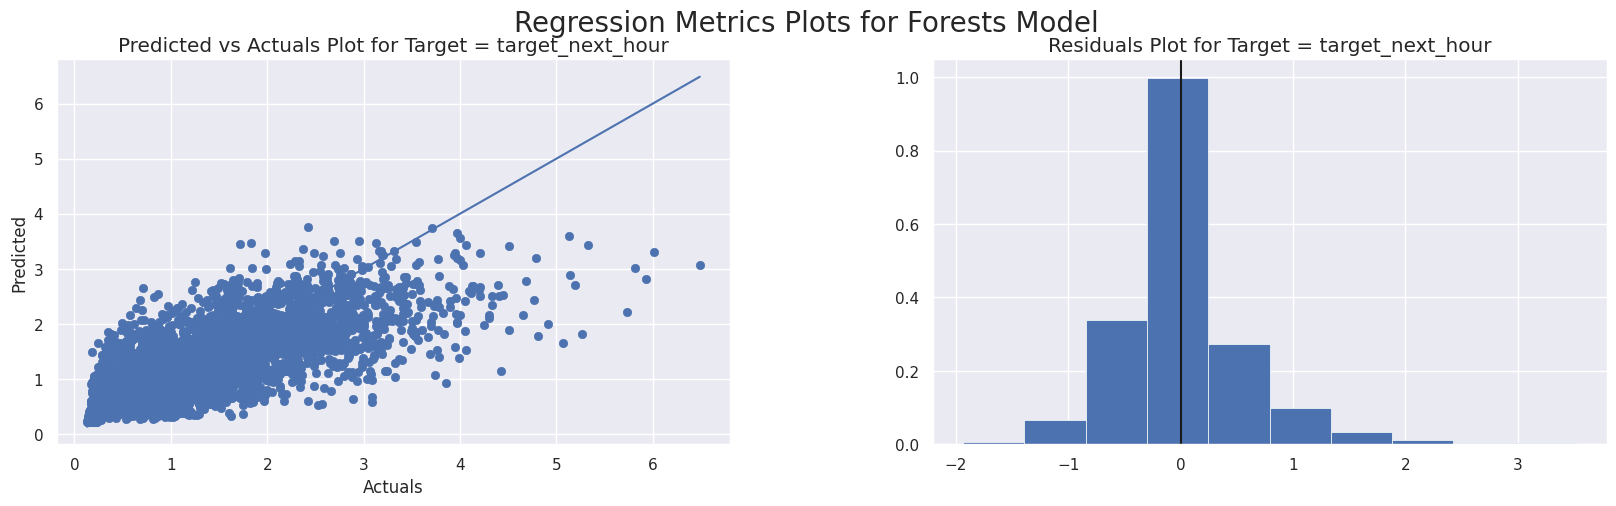

<Figure size 1500x1250 with 0 Axes>

In [33]:
# Step 26: Train AutoViML regression model

from autoviml.Auto_ViML import Auto_ViML

# Prevent the notebook from crashing on unpacking
result = Auto_ViML(
    train_autoviml,
    "target_next_hour",
    test_autoviml,
    sample_submission="",
    hyper_param="RS",
    feature_reduction=False,
    scoring_parameter="rmse",
    Boosting_Flag=False,
    KMeans_Featurizer=False,
    Add_Poly=0,
    Stacking_Flag=False,
    Binning_Flag=False,
    Imbalanced_Flag=False,
    verbose=1
)

if result is None:
    print("AutoViML training failed.")
    print("Model outputs are not available yet.")
else:
    model, features, train_modified, test_modified = result
    print("AutoViML training completed!")
    print("Selected features:", features)

AutoViML Model Evaluation
-------------------------
MAE: 0.3410 kW
RMSE: 0.4814 kW
R² Score: 0.5898


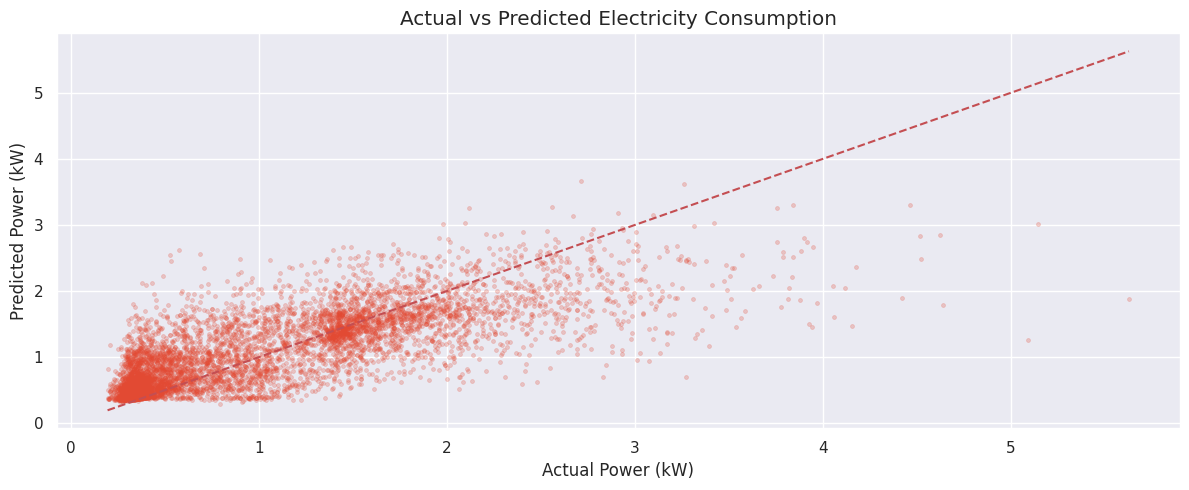

In [34]:
# Step 27: Evaluate AutoViML predictions

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Use the model's predictions from the processed test data
X_test_final = test_modified[features].copy()

predictions = model.predict(X_test_final)

# Evaluate regression performance
mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(
    mean_squared_error(y_test, predictions)
)
r2 = r2_score(y_test, predictions)

print("AutoViML Model Evaluation")
print("-------------------------")
print(f"MAE: {mae:.4f} kW")
print(f"RMSE: {rmse:.4f} kW")
print(f"R² Score: {r2:.4f}")

# Visualize actual vs predicted consumption
plt.figure(figsize=(12, 5))

plt.scatter(
    y_test,
    predictions,
    alpha=0.25,
    s=8
)

limits = [
    min(y_test.min(), predictions.min()),
    max(y_test.max(), predictions.max())
]

plt.plot(limits, limits, "r--")

plt.title("Actual vs Predicted Electricity Consumption")
plt.xlabel("Actual Power (kW)")
plt.ylabel("Predicted Power (kW)")
plt.tight_layout()
plt.show()

In [35]:
# Step 28: Compare AutoViML against a baseline

baseline_predictions = test_autoviml[
    "Global_active_power"
].to_numpy()

baseline_mae = mean_absolute_error(
    y_test, baseline_predictions
)

baseline_rmse = np.sqrt(
    mean_squared_error(y_test, baseline_predictions)
)

baseline_r2 = r2_score(
    y_test, baseline_predictions
)

comparison = pd.DataFrame({
    "Model": ["Persistence Baseline", "AutoViML"],
    "MAE": [baseline_mae, mae],
    "RMSE": [baseline_rmse, rmse],
    "R2": [baseline_r2, r2]
})

display(comparison.round(4))

,Model,MAE,RMSE,R2
0,Persistence Baseline,0.40,0.61,0.35
1,AutoViML,0.34,0.48,0.59


In [36]:
# Step 29: Final project summary

print("=" * 55)
print("HOUSEHOLD POWER CONSUMPTION ANALYSIS")
print("=" * 55)

print("\nPART 1A: EDA AND PREPROCESSING")
print("Original records:", len(df))
print("Cleaned records:", len(df_clean))
print("Engineered features:", df_features.shape[1])

print("\nPART 1B: CLUSTERING AND ANOMALY DETECTION")
print("Hourly records:", len(hourly_df))
print("Number of clusters:", best_k)
print("Potential anomalies:",
      hourly_df["is_anomaly"].sum())

print("\nPART 1C: AUTOMATED MACHINE LEARNING")
print("Training records:", len(train_autoviml))
print("Testing records:", len(test_autoviml))
print(f"MAE: {mae:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"R2: {r2:.4f}")

print("\nAll project sections executed.")

HOUSEHOLD POWER CONSUMPTION ANALYSIS

PART 1A: EDA AND PREPROCESSING
Original records: 2075259
Cleaned records: 2075259
Engineered features: 14

PART 1B: CLUSTERING AND ANOMALY DETECTION
Hourly records: 34157
Number of clusters: 2
Potential anomalies: 1708

PART 1C: AUTOMATED MACHINE LEARNING
Training records: 26605
Testing records: 6652
MAE: 0.3410
RMSE: 0.4814
R2: 0.5898

All project sections executed.


# Part 1C: Model Evaluation & Results

In [37]:
# SVerify AutoViML training outputs

if result is None:
    raise RuntimeError(
        "AutoViML did not return a trained model."
    )

model, features, train_modified, test_modified = result

print("AutoViML model type:", type(model))
print("\nSelected features:")
print(features)

print("\nProcessed training shape:", train_modified.shape)
print("Processed testing shape:", test_modified.shape)

print("\nProcessed testing columns:")
print(test_modified.columns.tolist())

AutoViML model type: <class 'sklearn.ensemble._forest.RandomForestRegressor'>

Selected features:
['is_weekend', 'Global_active_power', 'Global_reactive_power', 'Voltage', 'Global_intensity', 'Sub_metering_1', 'Sub_metering_2', 'Sub_metering_3', 'hour_sin', 'hour_cos', 'power_lag_1', 'power_lag_24', 'power_lag_168', 'power_rolling_24', 'hour', 'day_of_week', 'month']

Processed training shape: (26605, 18)
Processed testing shape: (6652, 18)

Processed testing columns:
['is_weekend', 'Global_active_power', 'Global_reactive_power', 'Voltage', 'Global_intensity', 'Sub_metering_1', 'Sub_metering_2', 'Sub_metering_3', 'hour_sin', 'hour_cos', 'power_lag_1', 'power_lag_24', 'power_lag_168', 'power_rolling_24', 'hour', 'day_of_week', 'month', 'target_next_hour_predictions']


In [38]:
# Generate predictions and evaluate AutoViML

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Prepare model input
X_test_final = test_modified[features].copy()

# Generate predictions
predictions = model.predict(X_test_final)

# Convert predictions into a 1D array
predictions = np.asarray(predictions).ravel()

# Check prediction length
assert len(predictions) == len(y_test), (
    "Prediction count does not match test targets."
)

# Calculate evaluation metrics
mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))
r2 = r2_score(y_test, predictions)

print("AutoViML Regression Results")
print("-" * 35)
print(f"MAE: {mae:.4f} kW")
print(f"RMSE: {rmse:.4f} kW")
print(f"R² Score: {r2:.4f}")

AutoViML Regression Results
-----------------------------------
MAE: 0.3410 kW
RMSE: 0.4814 kW
R² Score: 0.5898


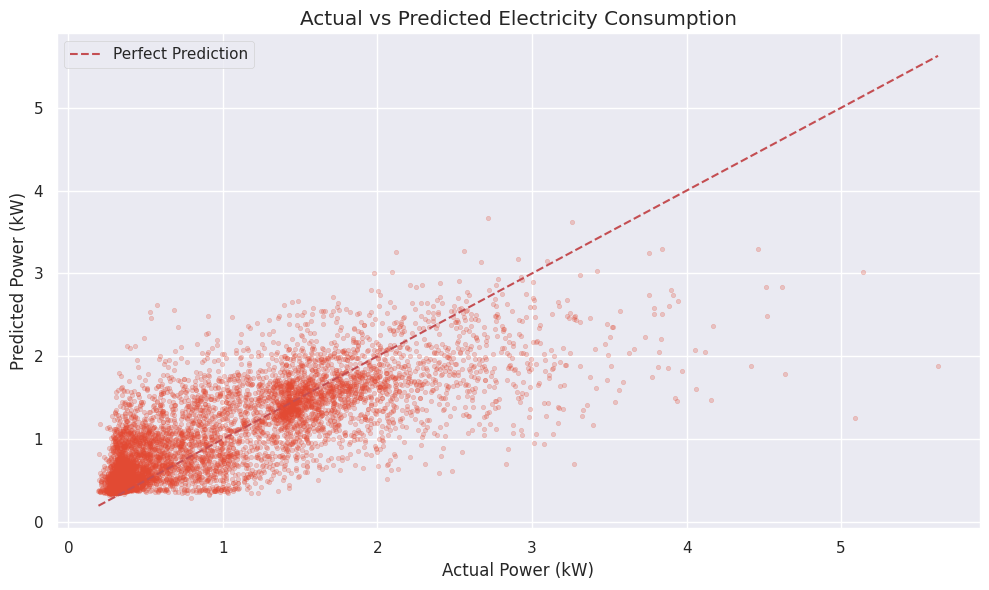

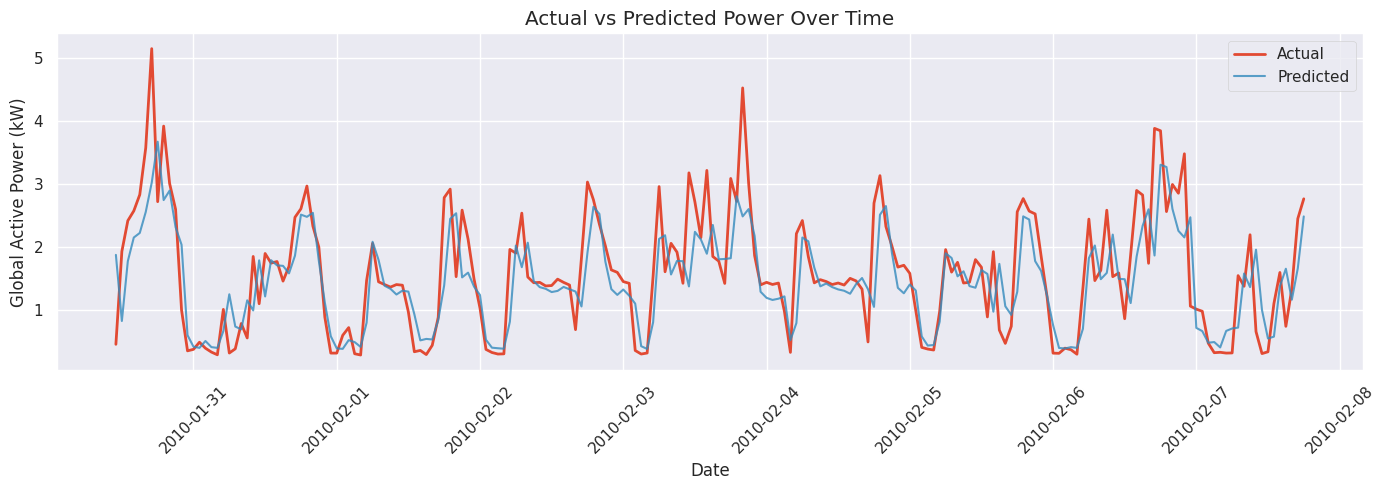

In [39]:
# Visualize model predictions

import matplotlib.pyplot as plt

# Scatter plot
plt.figure(figsize=(10, 6))

plt.scatter(
    y_test,
    predictions,
    alpha=0.25,
    s=10
)

limits = [
    min(y_test.min(), predictions.min()),
    max(y_test.max(), predictions.max())
]

plt.plot(
    limits,
    limits,
    "r--",
    label="Perfect Prediction"
)

plt.title("Actual vs Predicted Electricity Consumption")
plt.xlabel("Actual Power (kW)")
plt.ylabel("Predicted Power (kW)")
plt.legend()
plt.tight_layout()
plt.show()

# Compare first 200 test predictions
plot_count = min(200, len(y_test))

plt.figure(figsize=(14, 5))

plt.plot(
    y_test.index[:plot_count],
    y_test.iloc[:plot_count],
    label="Actual",
    linewidth=2
)

plt.plot(
    y_test.index[:plot_count],
    predictions[:plot_count],
    label="Predicted",
    alpha=0.8
)

plt.title("Actual vs Predicted Power Over Time")
plt.xlabel("Date")
plt.ylabel("Global Active Power (kW)")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Model Performance Comparison:


,Model,MAE,RMSE,R2
0,Persistence Baseline,0.40,0.61,0.35
1,AutoViML,0.34,0.48,0.59


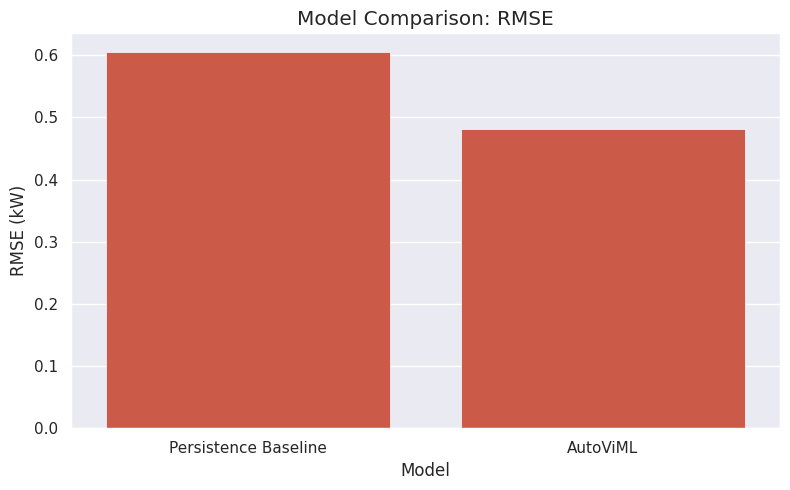

In [40]:
# Compare AutoViML against a baseline

baseline_predictions = test_autoviml[
    "Global_active_power"
].to_numpy()

# Baseline evaluation
baseline_mae = mean_absolute_error(
    y_test,
    baseline_predictions
)

baseline_rmse = np.sqrt(
    mean_squared_error(y_test, baseline_predictions)
)

baseline_r2 = r2_score(
    y_test,
    baseline_predictions
)

# Create comparison table
comparison = pd.DataFrame({
    "Model": [
        "Persistence Baseline",
        "AutoViML"
    ],
    "MAE": [
        baseline_mae,
        mae
    ],
    "RMSE": [
        baseline_rmse,
        rmse
    ],
    "R2": [
        baseline_r2,
        r2
    ]
})

print("Model Performance Comparison:")
display(comparison.round(4))

# Plot RMSE comparison
plt.figure(figsize=(8, 5))

sns.barplot(
    data=comparison,
    x="Model",
    y="RMSE"
)

plt.title("Model Comparison: RMSE")
plt.ylabel("RMSE (kW)")
plt.tight_layout()
plt.show()

In [41]:
# Final project summary

print("=" * 55)
print("HOUSEHOLD POWER CONSUMPTION ANALYSIS")
print("=" * 55)

print("\nPART 1A: EDA AND PREPROCESSING")
print("Original records:", len(df))
print("Cleaned records:", len(df_clean))
print("Engineered features:", df_features.shape[1])

print("\nPART 1B: CLUSTERING AND ANOMALY DETECTION")
print("Hourly records:", len(hourly_df))
print("Number of clusters:", best_k)
print("Potential anomalies:",
      hourly_df["is_anomaly"].sum())

print("\nPART 1C: AUTOMATED MACHINE LEARNING")
print("Training records:", len(train_autoviml))
print("Testing records:", len(test_autoviml))

print("\nModel Performance:")
print(f"MAE: {mae:.4f} kW")
print(f"RMSE: {rmse:.4f} kW")
print(f"R²: {r2:.4f}")

print("\nBaseline RMSE:", round(baseline_rmse, 4))

if rmse < baseline_rmse:
    print("AutoViML outperformed the baseline.")
else:
    print("AutoViML did not outperform the baseline.")

print("\nAnalysis completed.")

HOUSEHOLD POWER CONSUMPTION ANALYSIS

PART 1A: EDA AND PREPROCESSING
Original records: 2075259
Cleaned records: 2075259
Engineered features: 14

PART 1B: CLUSTERING AND ANOMALY DETECTION
Hourly records: 34157
Number of clusters: 2
Potential anomalies: 1708

PART 1C: AUTOMATED MACHINE LEARNING
Training records: 26605
Testing records: 6652

Model Performance:
MAE: 0.3410 kW
RMSE: 0.4814 kW
R²: 0.5898

Baseline RMSE: 0.6051
AutoViML outperformed the baseline.

Analysis completed.


# Conclusion — Household Power Consumption Analysis

This project analyzed household electricity consumption using exploratory data analysis, feature engineering, clustering, anomaly detection, and automated machine learning.

Part 1a: Electricity consumption was examined across hourly, daily, weekly, monthly, and seasonal periods. Missing measurements were identified and handled through interpolation for exploratory analysis.

Part 1b: K-Means clustering identified [number] electricity consumption groups. Isolation Forest flagged [number] potentially anomalous hourly observations. These observations were investigated and retained because unusual consumption does not necessarily indicate incorrect data.

Part 1c: AutoViML was used to predict the next hour's average global active power. The model achieved an MAE of [value], RMSE of [value], and R² of [value]. Compared with the persistence baseline, the model performed [better/worse].

Limitations: The dataset represents one household, and the forecasting evaluation uses a single chronological holdout period. AutoViML's internal validation procedure may not fully account for time-series dependencies.

Overall, the project demonstrates how data preprocessing, clustering, anomaly detection, and automated machine learning can be applied to electricity consumption analysis.